In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt

# XOR Problem

## What is the XOR operation?

* XOR is a boolean logic operation that compares two input bits and generates one output bit. 
* IF the bits are the same (or both are true) the result is 0 (or false).
* IF the bits are different the result is 1 (or true).

## What is the XOR problem?

* The XOR can be seen as a classification problem. 
*   You receive two inputs and you want to predict true or false, depending if the inputs are different or the same
* However, the inputs are not linearly separable. That means that there is no way to use a straight line to separate the possible options an make an automated prediction correctly.
* In the next figure we can se that it is not possible to separate the red dots and the green dots with a straight line. 

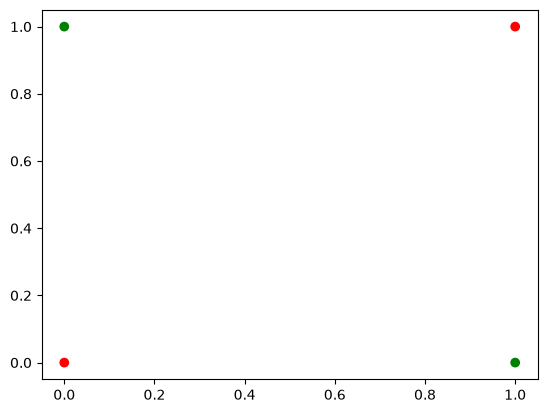

In [2]:
plt.scatter([0, 0, 1, 1], [0,1,1,0], c=['red', 'green', 'red', 'green'])
plt.show()

# Using a Multilayer Perceptron (MLP) architecture

* A MLP with an input and an output layer is not capable of solving the problem since it the result are linear solutions.
* However, if we add a hidden layer to the MLP, the network will be capable of achieving non-linear separation and correctly predict the results.

#  Training a MLP with a single hidden layer to solve the XOR problem


In [3]:
# First we define the input data (X) and the output data (Y) that we are going to use for training
X = tf.constant([[0,0], [0,1], [1,0], [1,1]], dtype=tf.float32)
Y = tf.constant([[0],[1],[1],[0]], dtype=tf.float32)

In [4]:
# Here we define the architecture of our network. 
#   The number of neurons in the input layer is defined by the number of input values in our dataset, in this case 2. 
#   For this architecture we are going to use 2 neurons in our hidden layer.
#   The number of neurons in the output layer is defined by the number of expected values, in this case we expect a single value 1 or 0.
model =  tf.keras.models.Sequential() # we create a Neural Network model that is Sequential, which means each layer we add will be connected to the previous one. 
model.add(tf.keras.Input(shape=(2,))) # Input layer
model.add(tf.keras.layers.Dense(2, activation='sigmoid')) # Hidden Layer
model.add(tf.keras.layers.Dense(1, activation='sigmoid')) # Output Layer

In [5]:
# We define which optimizer and which error loss are we using to update the weights of the network.
sgd = tf.keras.optimizers.SGD(learning_rate=0.8,momentum=0.3)
mse = tf.keras.losses.MeanSquaredError()

In [6]:
# we compile our model 
model.compile(optimizer=sgd, loss=mse, metrics=['accuracy'])

In [7]:
# After compiling the model we are able to start the training using the 'fit' function. 
# We need to make use of our training dataset (X and Y).
# We also specify the number of epochs (or iterations) the network is going to train for.
model.fit(X, Y, epochs=1000)

Epoch 1/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - accuracy: 0.5000 - loss: 0.3208
Epoch 2/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step - accuracy: 0.5000 - loss: 0.3081
Epoch 3/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 0.5000 - loss: 0.2927
Epoch 4/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - accuracy: 0.5000 - loss: 0.2787
Epoch 5/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.5000 - loss: 0.2676
Epoch 6/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step - accuracy: 0.5000 - loss: 0.2599
Epoch 7/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - accuracy: 0.5000 - loss: 0.2549
Epoch 8/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.5000 - loss: 0.2519
Epoch 9/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 178ms/step - accuracy: 0.5000 - loss: 0.2502
Epoch 10/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 100ms/step - accuracy: 0.5000 - loss: 0.2492
Epoch 11/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step - accuracy: 0.5000 - loss: 0.2487
Epoch 12/1000
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 213ms/step - accurac

In [8]:
# After our model finished training we can test it and see how well it predicts 
model.predict(X)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step


array([[0.08062157],
       [0.92230815],
       [0.4958544 ],
       [0.5091958 ]], dtype=float32)